# Лабораторная №1. Scan-matching. Шаврин А.П. Виноградова М.О.

## Imports

In [4]:
from __future__ import annotations
from dataclasses import dataclass
from functools import cached_property
import math
import time
import numpy as np
from scipy.ndimage import distance_transform_edt, maximum_filter, gaussian_filter
import matplotlib.pyplot as plt

## Core

In [ ]:
@dataclass(frozen=True, slots=True)
class Point:
    x: float
    y: float


@dataclass(frozen=True, slots=True)
class Vector:
    x: float
    y: float


@dataclass(frozen=True, slots=True)
class Segment:
    a: Point
    b: Point


@dataclass(frozen=True, slots=True)
class Ray:
    origin: Point
    direction: Vector

    @classmethod
    def from_angle(cls, origin: Point, angle: float) -> "Ray":
        return cls(origin, Vector(math.cos(angle), math.sin(angle)))


@dataclass(frozen=True, slots=True)
class Pose:
    position: Point
    theta: float

    def compose(self, other: Pose) -> Pose:
        c, s = math.cos(self.theta), math.sin(self.theta)
        return Pose(
            position=Point(
                x = c * other.position.x - s * other.position.y + self.position.x,
                y = s * other.position.x + c * other.position.y + self.position.y
            ),
            theta = self.theta + other.theta,
        )

    def inverse(self) -> Pose:
        c, s = math.cos(self.theta), math.sin(self.theta)
        return Pose(
            position=Point(
                x = -c * self.position.x - s * self.position.y,
                y = s * self.position.x - c * self.position.y
            ),
            theta = -self.theta,
        )

    def apply(self, pts: np.ndarray) -> np.ndarray:
        c, s = math.cos(self.theta), math.sin(self.theta)
        R = np.array([[c, -s], [s, c]])
        return pts @ R.T + np.array([self.position.x, self.position.y])


@dataclass(frozen=True, slots=True)
class Scan:
    angles: np.ndarray
    ranges: np.ndarray

    def __post_init__(self):
        if len(self.angles) != len(self.ranges):
            raise ValueError(f"angles ({len(self.angles)}) != ranges ({len(self.ranges)})")
        self.angles.flags.writeable = False
        self.ranges.flags.writeable = False


@dataclass
class Room:
    polygon: list[Point]    # вершины против часовой

    @property
    def n_vertices(self) -> int:
        return len(self.polygon)

    @cached_property
    def segments(self) -> list[Segment]:
        n = self.n_vertices
        return [Segment(self.polygon[i], self.polygon[(i+1)%n]) for i in range(n)]


@dataclass(frozen=True)
class OccupancyMap:
    prob: np.ndarray                    # (H, W), в [0, 1]
    origin: tuple[float, float]         # (x0, y0) — левый нижний угол
    resolution: float                   # м/клетка

    def __post_init__(self):
        self.prob.flags.writeable = False

    @property
    def shape(self) -> tuple[int, int]:
        return self.prob.shape

    @property
    def extent(self) -> tuple[float, float, float, float]:
        """(x_min, x_max, y_min, y_max) — для imshow в matplotlib."""
        x0, y0 = self.origin
        H, W = self.prob.shape
        return x0, x0 + W * self.resolution, y0, y0 + H * self.resolution


@dataclass(frozen=True, slots=True)
class SearchLevel:
    xy_range: float     # половина окна по x и y
    theta_range: float  # половина окна по углу
    xy_step: float      # шаг перебора по x и y
    theta_step: float   # шаг перебора по углу
    n_best: int         # число лучших на след уровень

## Pose generator

In [ ]:
class PoseGenerator:
    def __init__(self, room, rng, wall_margin=0.5, column_margin=0.3):
        self.room = room
        self.rng = rng
        self.wall_margin = wall_margin
        self.column_margin = column_margin

    @staticmethod
    def _signed_dist_to_wall(p, seg):
        ax, ay = seg.a.x, seg.a.y
        ex, ey = seg.b.x - ax, seg.b.y - ay
        cross = ex * (p.y - ay) - ey * (p.x - ax)
        return cross / math.hypot(ex, ey)

    def is_valid(self, pose):
        p = pose.position
        for seg in self.room.segments:
            if self._signed_dist_to_wall(p, seg) < self.wall_margin:
                return False

        return True

    def random(self, tries=10_000):
        xs = [q.x for q in self.room.polygon]
        ys = [q.y for q in self.room.polygon]
        for _ in range(tries):
            x = self.rng.uniform(min(xs), max(xs))
            y = self.rng.uniform(min(ys), max(ys))
            theta = self.rng.uniform(-np.pi, np.pi)
            pose = Pose(Point(x, y), theta)
            if self.is_valid(pose):
                return pose
        raise RuntimeError("не удалось сгенерировать валидную позу")

## RayCaster

In [ ]:
class RayCaster:
    _EPS = 1e-9
    _EPS_PARALLEL = 1e-9

    def intersect_segment(self, ray: Ray, seg: Segment) -> float | None:
        ox, oy = ray.origin.x, ray.origin.y
        dx, dy = ray.direction.x, ray.direction.y
        ax, ay = seg.a.x, seg.a.y
        ex, ey = seg.b.x - ax, seg.b.y - ay

        denom = dx * ey - dy * ex
        if abs(denom) < self._EPS_PARALLEL * math.hypot(ex, ey):
            return None

        t = ((ax - ox) * ey - (ay - oy) * ex) / denom
        u = ((ax - ox) * dy - (ay - oy) * dx) / denom
        if t > self._EPS and 0.0 <= u <= 1.0:
            return float(t)
        return None


    def cast(self, ray: Ray, room: Room) -> float | None:
        best = None
        for seg in room.segments:
            t = self.intersect_segment(ray, seg)
            if t is not None and (best is None or t < best):
                best = t
        return best

## Lidar

In [65]:
ANGLE_STEP = math.pi / 360
MAX_RANGE = 10.0
NOISE_STD = 0.02


class Lidar:
    def __init__(self, ray_caster: RayCaster  | None = None, angle_step: float = ANGLE_STEP, max_range: float = MAX_RANGE, noise_std: float = NOISE_STD):
        self.ray_caster = ray_caster if ray_caster is not None else RayCaster()
        self.angle_step = angle_step
        self.max_range = max_range
        self.noise_std = noise_std

    @property
    def num_rays(self) -> int:
        return int(round(2 * math.pi / self.angle_step))

    def scan(self, pose: Pose, room: Room, rng: np.random.Generator | None = None) -> Scan:
        n = self.num_rays
        angles = np.arange(n) * self.angle_step
        ranges = np.empty(n)

        for i, a in enumerate(angles):
            ray = Ray.from_angle(pose.position, pose.theta + a)
            t = self.ray_caster.cast(ray, room)
            ranges[i] = t if t is not None and t < self.max_range else math.nan

        if rng is not None:
            ranges = ranges + rng.normal(0, self.noise_std, len(ranges))

        mask = ~np.isnan(ranges)
        return Scan(angles=angles[mask], ranges=ranges[mask])

## Scan matching

In [9]:
def polar_to_local(scan: Scan) -> np.ndarray:
    return np.column_stack([scan.ranges * np.cos(scan.angles), scan.ranges * np.sin(scan.angles)])

In [ ]:
RESOLUTION = 0.05
PADDING = 1.0


from scipy.ndimage import distance_transform_edt, maximum_filter, gaussian_filter
from skimage.draw import line as skimage_line

class ScanMatcher:
    def __init__(
        self,
        resolution: float = 0.05,
        padding: float = 1.0,
        search_xy_range: float = 8.0,
        search_theta_range: float = math.pi,
        score_threshold: float = 20.0
    ):
        self.resolution = resolution
        self.padding = padding
        self.W_xy = search_xy_range
        self.W_theta = search_theta_range
        self.score_threshold = score_threshold

    @staticmethod
    def _bresenham(x0: int, y0: int, x1: int, y1: int) -> list[tuple[int, int]]:
        rr, cc = skimage_line(y0, x0, y1, x1)
        return list(zip(cc.tolist(), rr.tolist()))

    def build_map(self, scan: Scan) -> OccupancyMap:
        points = polar_to_local(scan)
        if len(points) == 0:
            raise ValueError("empty scan")

        pad = self.padding
        x_min, y_min = points.min(axis=0) - pad
        x_max, y_max = points.max(axis=0) + pad
        W = int(np.ceil((x_max - x_min) / self.resolution))
        H = int(np.ceil((y_max - y_min) / self.resolution))

        ix = ((points[:, 0] - x_min) / self.resolution).astype(int)
        iy = ((points[:, 1] - y_min) / self.resolution).astype(int)
        ok_hit = (ix >= 0) & (ix < W) & (iy >= 0) & (iy < H)

        log_odds = np.zeros((H, W), dtype=np.float32)

        p_hit, p_miss = 0.7, 0.4
        l_hit  = math.log(p_hit  / (1 - p_hit))    # = +0.847
        l_miss = math.log(p_miss / (1 - p_miss))   # = -0.405

        np.add.at(log_odds, (iy[ok_hit], ix[ok_hit]), l_hit)

        ox = int((0.0 - x_min) / self.resolution)
        oy = int((0.0 - y_min) / self.resolution)
        for xh, yh in zip(ix[ok_hit], iy[ok_hit]):
            for px, py in self._bresenham(ox, oy, xh, yh)[:-1]:
                if 0 <= px < W and 0 <= py < H:
                    log_odds[py, px] += l_miss

        L_min, L_max = -2.0, 3.5
        np.clip(log_odds, L_min, L_max, out=log_odds)

        prob = (1.0 / (1.0 + np.exp(-log_odds))).astype(np.float32)
        prob[log_odds == 0] = 0.3

        return OccupancyMap(prob, (float(x_min), float(y_min)), self.resolution)

    def _score_with_grid(self, delta, pts, occ, grid):
        pts_t = delta.apply(pts)
        x0, y0 = occ.origin
        ix = ((pts_t[:, 0] - x0) / occ.resolution).astype(int)
        iy = ((pts_t[:, 1] - y0) / occ.resolution).astype(int)
        H, W = occ.shape
        ok = (ix >= 0) & (ix < W) & (iy >= 0) & (iy < H)
        if not ok.any():
            return 0.0
        s = float(grid[iy[ok], ix[ok]].sum())
        return s

    def _precompute(self, prob, max_h):
        grids = [prob]
        for h in range(1, max_h + 1):
            grids.append(maximum_filter(prob, size=2 ** (h + 1), mode="nearest"))
        return grids

    def match(
        self, occ: OccupancyMap, scan: Scan, initial: Pose | None = None
    ) -> Pose:
        if initial is None:
            initial = Pose(Point(0.0, 0.0), 0.0)
        pts = polar_to_local(scan)
        if len(pts) == 0:
            return initial

        # ─── 1. Размеры сетки поиска ───
        r = self.resolution
        d_max = float(np.linalg.norm(pts, axis=1).max())
        d_theta = (
            math.acos(1 - r * r / (2 * d_max * d_max)) if d_max > r
            else math.pi / 18
        )

        w_x = int(self.W_xy / r)
        w_y = int(self.W_xy / r)
        w_theta = int(self.W_theta / d_theta)

        # ─── 2. precomputed grids ───
        max_h = 1
        while (1 << max_h) <= 2 * w_x:
            max_h += 1
        max_h = min(max_h, 6)
        precomp = self._precompute(occ.prob, max_h)

        # ─── 3. дети корня (уровень h0) ───
        h0 = max_h
        step0 = 1 << h0
        C0 = [
            (cx, cy, cth, h0)
            for cx in range(-w_x, w_x + 1, step0)
            for cy in range(-w_y, w_y + 1, step0)
            for cth in range(-w_theta, w_theta + 1)
        ]

        def pose_of_node(cx, cy, cth, h):
            offset = ((1 << h) - 1) / 2
            return Pose(
                Point(
                    initial.position.x + r * (cx + offset),
                    initial.position.y + r * (cy + offset),
                ),
                initial.theta + d_theta * cth,
            )

        def upper_bound(cx, cy, cth, h):
            p = pose_of_node(cx, cy, cth, h)
            grid = precomp[min(h, len(precomp) - 1)]
            return self._score_with_grid(p, pts, occ, grid)

        def leaf_score(cx, cy, cth):
            p = pose_of_node(cx, cy, cth, 0)
            return self._score_with_grid(p, pts, occ, occ.prob)

        # ─── 4. DFS BnB ───
        best_score = self.score_threshold
        best_pose = None

        C0_scores = [(upper_bound(*c), c) for c in C0]
        C0_scores.sort(key=lambda t: -t[0])
        stack = [c for _, c in reversed(C0_scores)]

        while stack:
            cx, cy, cth, h = stack.pop()

            b = upper_bound(cx, cy, cth, h)
            if b <= best_score:
                continue  # отсечение

            if h == 0:
                s = leaf_score(cx, cy, cth)
                if s > best_score:
                    best_score = s
                    best_pose = pose_of_node(cx, cy, cth, 0)
            else:
                h_new = h - 1
                step_new = 1 << h_new
                children = [
                    (cx,            cy,            cth, h_new),
                    (cx + step_new, cy,            cth, h_new),
                    (cx,            cy + step_new, cth, h_new),
                    (cx + step_new, cy + step_new, cth, h_new),
                ]
                children = [
                    c for c in children
                    if -w_x <= c[0] <= w_x and -w_y <= c[1] <= w_y
                ]
                children_scores = [(upper_bound(*c), c) for c in children]
                children_scores.sort(key=lambda t: -t[0])
                for _, c in reversed(children_scores):
                    stack.append(c)

        return best_pose if best_pose is not None else initial

## Vizualizer

In [42]:
class ScanVisualizer:
    def __init__(self, room: Room, figsize=(14, 12), dpi=100):
        self.room = room
        self.figsize = figsize
        self.dpi = dpi

    def _draw_room(self, ax):
        poly = np.array([[p.x, p.y] for p in self.room.polygon])
        poly = np.vstack([poly, poly[0]])
        ax.plot(poly[:, 0], poly[:, 1], "k-", lw=2, label="room")
        for col in self.room.columns:
            ax.add_patch(plt.Circle((col.center.x, col.center.y), col.radius, color="gray", alpha=0.4))

    def _draw_robot(self, ax, pose: Pose, color, label=None):
        ax.plot(
            pose.position.x,
            pose.position.y,
            "o",
            color=color,
            markeredgecolor="black",
            ms=9,
            label=label
        )
        ax.arrow(
            pose.position.x,
            pose.position.y,
            0.6 * math.cos(pose.theta),
            0.6 * math.sin(pose.theta),
            head_width=0.2,
            color=color,
            length_includes_head=True
        )

    def _draw_scan_local(self, ax, pts, color, title):
        ax.scatter(*pts.T, s=4, c=color, alpha=0.7)
        ax.plot(0, 0, "o", color=color, markeredgecolor="black", ms=10)
        ax.arrow(0, 0, 0.6, 0, head_width=0.2, color=color, length_includes_head=True)
        ax.set_aspect("equal")
        ax.grid(alpha=0.3)
        ax.set_xlim(-10, 10)
        ax.set_ylim(-10, 10)
        ax.set_title(title)
        ax.set_xlabel("x, m")
        ax.set_ylabel("y, m")

    def plot_scan_setup(self, pose1: Pose, pose2: Pose, scan1: Scan, scan2: Scan, delta_true, figsize=(14, 12)):
        pts1_local = polar_to_local(scan1)
        pts2_local = polar_to_local(scan2)
        pts1_world = pose1.apply(pts1_local)
        pts2_world = pose2.apply(pts2_local)

        fig, axes = plt.subplots(2, 2, figsize=figsize)

        # [0,0] мир
        ax = axes[0, 0]
        self._draw_room(ax)
        ax.scatter(*pts1_world.T, s=4, c="tab:blue",  alpha=0.7, label="scan1")
        ax.scatter(*pts2_world.T, s=4, c="tab:green", alpha=0.7, label="scan2")
        self._draw_robot(ax, pose1, "tab:blue",  "pose1")
        self._draw_robot(ax, pose2, "tab:green", "pose2")
        ax.set_aspect("equal"); ax.grid(alpha=0.3)
        ax.set_title("World: room + both scans + both poses")
        ax.set_xlabel("x, m"); ax.set_ylabel("y, m")
        ax.legend(fontsize=8, loc="best")

        # [0,1] scan1 локально
        self._draw_scan_local(axes[0, 1], pts1_local, "tab:blue", f"scan1 in robot-1 frame ({len(scan1.ranges)} rays)")

        # [1,0] scan2 локально
        self._draw_scan_local(axes[1, 0], pts2_local, "tab:green", f"scan2 in robot-2 frame ({len(scan2.ranges)} rays)")

        # [1,1] цель для матчера
        ax = axes[1, 1]
        ax.scatter(*pts1_local.T, s=4, c="tab:blue", alpha=0.7, label="scan1")
        ax.scatter(*delta_true.apply(pts2_local).T, s=4, c="tab:green", alpha=0.7, label="scan2 x delta_true")
        ax.plot(0, 0, "o", color="black", ms=8)
        ax.arrow(0, 0, 0.6, 0, head_width=0.2, color="black", length_includes_head=True)
        ax.set_aspect("equal"); ax.grid(alpha=0.3)
        ax.set_title(f"Target: both in robot-1 frame (delta_theta = {math.degrees(delta_true.theta):+.1f}°)")
        ax.set_xlabel("x, m"); ax.set_ylabel("y, m")
        ax.legend(fontsize=8, loc="best")

        plt.tight_layout()
        return fig, axes

    def plot_match_result(self, pose1: Pose, pose2: Pose,
                      scan1: Scan, scan2: Scan, occ: OccupancyMap, delta_est: Pose,
                      rel_pos_err: float | None = None,
                      show: bool = True):
        """3 панели: мир / occupancy map (только scan1) / совмещение."""
        pts1 = polar_to_local(scan1)
        pts2 = polar_to_local(scan2)

        pts1_world = pose1.apply(pts1)
        pts2_world = pose2.apply(pts2)

        p2_est_in1 = delta_est.apply(pts2)   # scan2 в СК робота-1

        fig, axes = plt.subplots(1, 3, figsize=(21, 7))

        # ── (1) Мир: комната + оба скана + обе позы ──
        ax = axes[0]
        self._draw_room(ax)
        ax.scatter(*pts1_world.T,      s=3, c="tab:blue",  alpha=0.6, label="scan1")
        ax.scatter(*pts2_world.T, s=3, c="tab:green", alpha=0.5, label="scan2")
        self._draw_robot(ax, pose1,     "tab:blue",  "pose1")
        self._draw_robot(ax, pose2,     "tab:green", "pose2")
        ax.set_aspect("equal"); ax.grid(alpha=0.3)
        ax.set_title("World: room + scans + poses")
        ax.set_xlabel("x, m"); ax.set_ylabel("y, m")
        ax.legend(fontsize=8, loc="best")

        # ── (2) Occupancy map — только scan1 ──
        ax = axes[1]
        ax.imshow(occ.prob, origin="lower", extent=occ.extent,
                cmap="Greys", vmin=0, vmax=1)
        ax.scatter(*pts1.T, s=4, c="tab:blue", alpha=0.7, label="scan1")
        self._draw_robot(ax, Pose(Point(0.0, 0.0), 0.0), "lime", "robot-1")

        x0, x1, y0, y1 = occ.extent
        ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)

        ax.set_aspect("equal"); ax.grid(alpha=0.3)
        title = "Occupancy map (scan1 only)"
        if rel_pos_err is not None:
            title += f"\nerr = {rel_pos_err:.2f}% of diag"
        ax.set_title(title)
        ax.set_xlabel("x, m"); ax.set_ylabel("y, m")
        ax.legend(fontsize=8, loc="best")

        # ── (3) Совмещение: scan1 + scan2 × delta_est ──
        ax = axes[2]
        ax.scatter(*pts1.T,       s=4, c="tab:blue", alpha=0.6, label="scan1")
        ax.scatter(*p2_est_in1.T, s=4, c="tab:red",  alpha=0.6,
                label=r"scan2 × $\delta_{est}$")
        self._draw_robot(ax, Pose(Point(0.0, 0.0), 0.0), "lime", "robot-1")
        self._draw_robot(ax, delta_est, "tab:green", "robot-2 (est)")
        ax.set_aspect("equal"); ax.grid(alpha=0.3)
        ax.set_title(
            "Aligned in robot-1 frame\n"
            f"Δ_est = ({delta_est.position.x:+.2f}, "
            f"{delta_est.position.y:+.2f}, "
            f"{math.degrees(delta_est.theta):+.1f}°)")
        ax.set_xlabel("x, m"); ax.set_ylabel("y, m")
        ax.legend(fontsize=8, loc="best")

        plt.tight_layout()
        if show:
            plt.show()
        return fig, axes


## Тест

### Параметры комнаты

In [87]:
ROOM = Room(
    polygon=[
        Point(0.0, 0.0),
        Point(10.0, 0.0),
        Point(10.0, 2.0),
        Point(7.0, 5.0),
        Point(5.0, 5.0),
    ],
    columns=[
        # Circle(Point(3.0, 2.5), 0.4),
        # Circle(Point(6.5, 4.5), 0.7),
    ],
)

### Генерация поз и сканов

In [88]:
rng = np.random.default_rng(16)
gen = PoseGenerator(ROOM, rng=np.random.default_rng(16))
pose1 = gen.random()
pose2 = gen.random()

lidar = Lidar()
scan1 = lidar.scan(pose1, ROOM, rng=rng)
scan2 = lidar.scan(pose2, ROOM, rng=rng)
delta_true = pose1.inverse().compose(pose2)

# Сводка
print(f"Room:\t{len(ROOM.polygon)} vertices, {len(ROOM.columns)} columns")
print(f"Lidar:\t{lidar.num_rays} rays,  max={lidar.max_range} m,  sigma={lidar.noise_std} m")
print(f"pose1:\t({pose1.position.x:+.3f}, {pose1.position.y:+.3f}, "
      f"{math.degrees(pose1.theta):+.1f})")
print(f"pose2:\t({pose2.position.x:+.3f}, {pose2.position.y:+.3f}, "
      f"{math.degrees(pose2.theta):+.1f})")
print(f"delta:\t({delta_true.position.x:+.3f}, {delta_true.position.y:+.3f}, "
      f"{math.degrees(delta_true.theta):+.1f})")

Room:	5 vertices, 0 columns
Lidar:	720 rays,  max=10.0 m,  sigma=0.02 m
pose1:	(+5.669, +2.154, -146.1)
pose2:	(+8.024, +0.924, +70.4)
delta:	(-1.270, +2.333, +216.6)


### Визуализация поз и сканов

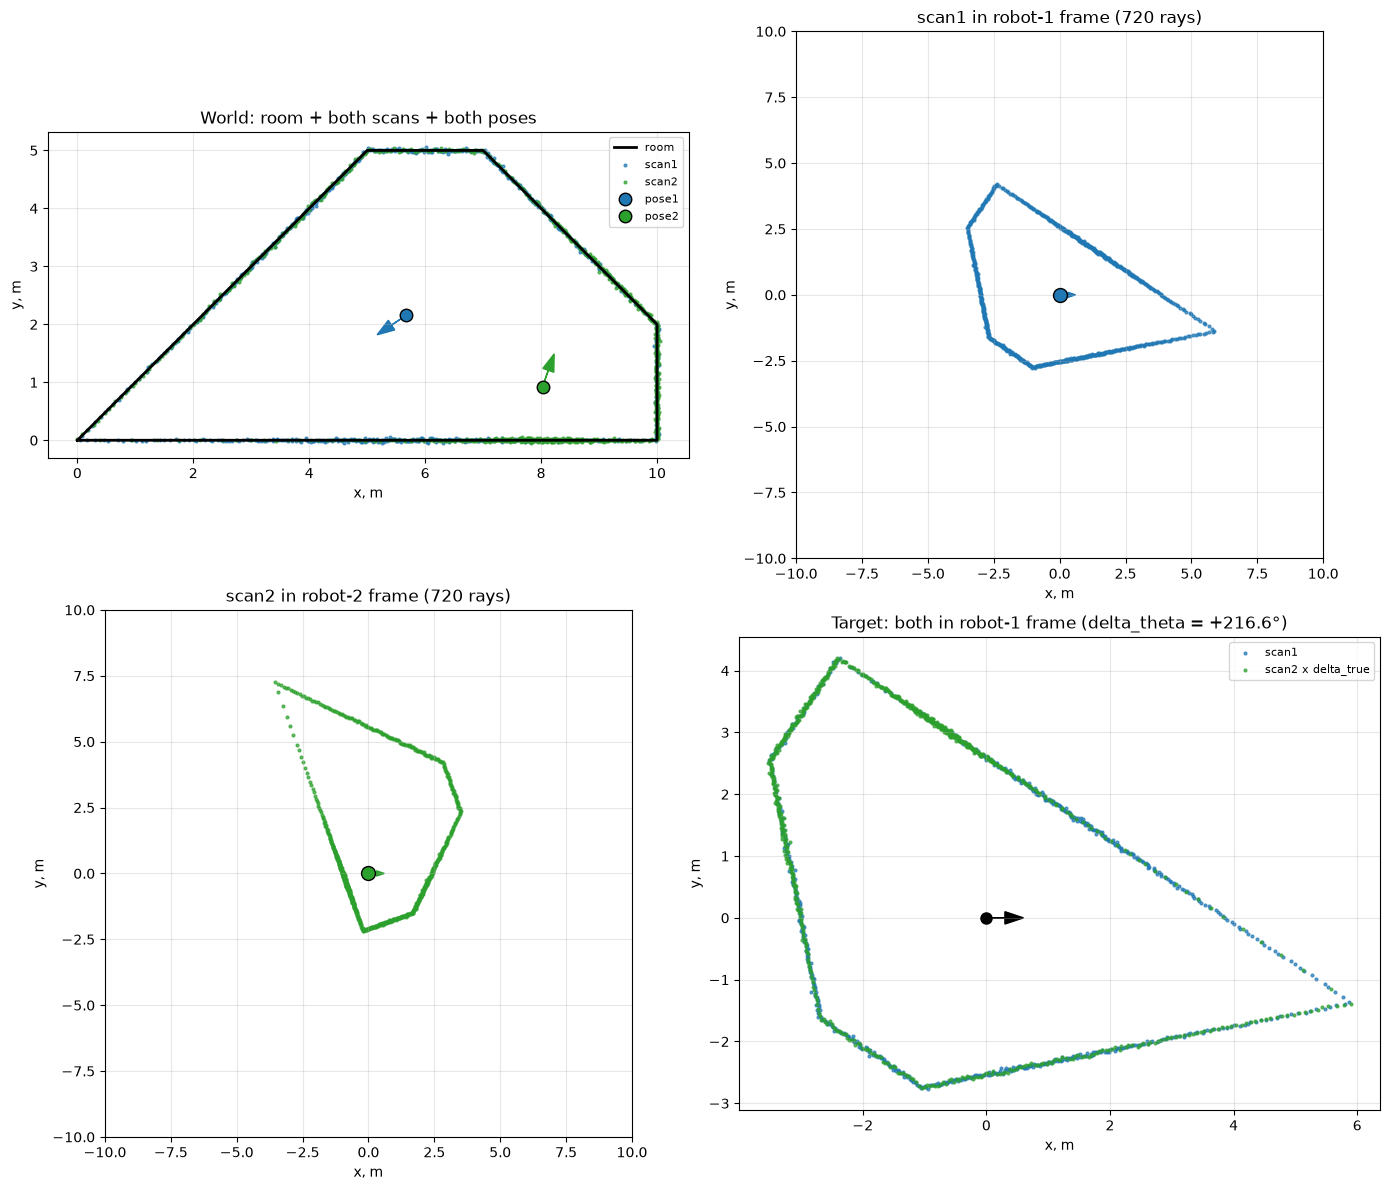

In [89]:
viz = ScanVisualizer(ROOM)
fig, axes = viz.plot_scan_setup(pose1, pose2, scan1, scan2, delta_true=delta_true)
plt.show()

### Построение карты занятости по scan1

In [92]:
matcher = ScanMatcher()
occ = matcher.build_map(scan1)

t0 = time.perf_counter()
delta_est = matcher.match(occ, scan2)
elapsed = time.perf_counter() - t0

pose2_est = pose1.compose(delta_est)
pos_err = np.hypot(pose2_est.position.x - pose2.position.x, pose2_est.position.y - pose2.position.y)
ang_err = abs(pose2_est.theta - pose2.theta)
ang_err = min(ang_err, 2 * math.pi - ang_err)

xs = [p.x for p in ROOM.polygon]
ys = [p.y for p in ROOM.polygon]
diag = math.hypot(max(xs) - min(xs), max(ys) - min(ys))
rel_pos_err = 100 * pos_err / diag

print("Scan Matching")
print(f"\tTime: {elapsed*1000:.0f} ms")
print(f"\tMap: {occ.shape[0]}×{occ.shape[1]} cells, {occ.resolution*100:.1f} cm/cell")
print()
print(f"\tTrue delta: ({delta_true.position.x:+.3f}, {delta_true.position.y:+.3f}, {math.degrees(delta_true.theta):+.2f})")
print(f"\tEst delta: ({delta_est.position.x:+.3f}, {delta_est.position.y:+.3f}, {math.degrees(delta_est.theta):+.2f})")
print()
print(f"\tPose error: {pos_err:.3f} m = {rel_pos_err:.2f}% of diagonal")
print(f"\tAngle error: {math.degrees(ang_err):.2f} in grads")

Scan Matching
	Time: 7889 ms
	Map: 180×228 cells, 5.0 cm/cell

	True delta: (-1.270, +2.333, +216.56)
	Est delta: (-1.250, +2.350, -143.66)

	Pose error: 0.026 m = 0.23% of diagonal
	Angle error: -0.22 in grads


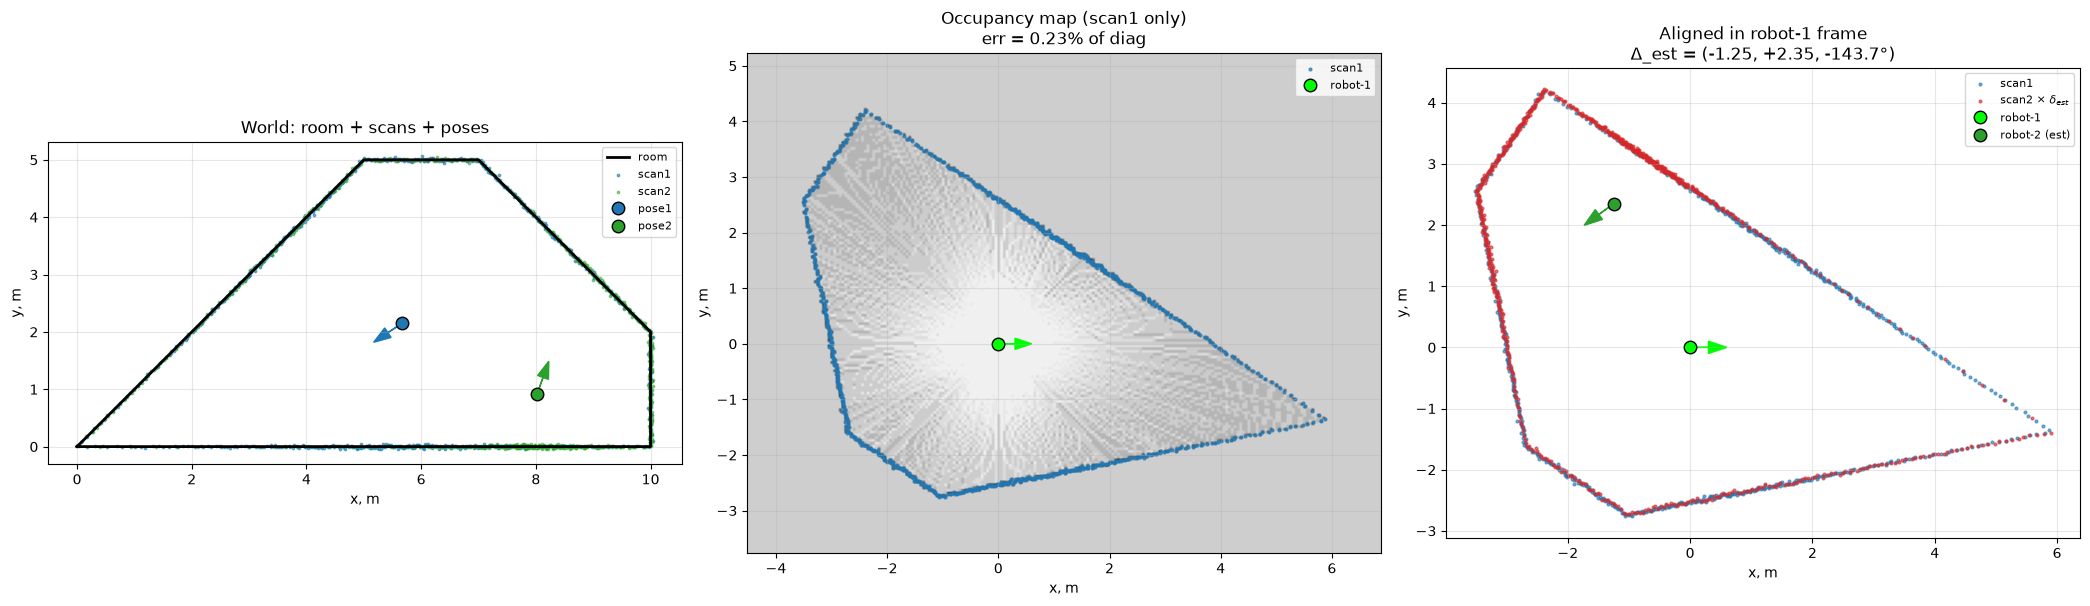

In [93]:
fig, axes = viz.plot_match_result(
    pose1, pose2, scan1, scan2, occ,
    delta_est, rel_pos_err=rel_pos_err,
)

In [98]:
def benchmark_matcher(room, n_runs=30, seed0=0, verbose=True):
    xs = [p.x for p in room.polygon]
    ys = [p.y for p in room.polygon]
    diag = math.hypot(max(xs) - min(xs), max(ys) - min(ys))

    results = []
    t_start = time.perf_counter()

    for i in range(n_runs):
        rng = np.random.default_rng(seed0 + i)
        gen = PoseGenerator(room, rng=rng)
        pose1, pose2 = gen.random(), gen.random()

        lidar = Lidar()
        scan1 = lidar.scan(pose1, room, rng=rng)
        scan2 = lidar.scan(pose2, room, rng=rng)
        delta_true = pose1.inverse().compose(pose2)

        matcher = ScanMatcher()
        occ = matcher.build_map(scan1)

        t0 = time.perf_counter()
        delta_est = matcher.match(occ, scan2)
        dt = time.perf_counter() - t0

        pose2_est = pose1.compose(delta_est)
        pos_err = np.hypot(pose2_est.position.x - pose2.position.x,
                           pose2_est.position.y - pose2.position.y)
        ang_err = abs(pose2_est.theta - pose2.theta)
        ang_err = min(ang_err, 2 * math.pi - ang_err)
        rel_pct = 100 * pos_err / diag

        results.append({
            "seed":          seed0 + i,
            "time_s":        dt,
            "pos_err_m":     pos_err,
            "ang_err_deg":   math.degrees(ang_err),
            "rel_err_pct":   rel_pct,
            "delta_true":    delta_true,
            "delta_est":     delta_est,
        })

        if verbose and (i + 1) % 10 == 0:
            print(f"  run {i+1:3d}/{n_runs}  "
                  f"(last: pos_err={pos_err*100:.2f} cm, "
                  f"ang_err={math.degrees(ang_err):.2f}°)")

    total = time.perf_counter() - t_start

    # ─── сводка ───
    errs  = np.array([r["rel_err_pct"] for r in results])
    pes   = np.array([r["pos_err_m"]   for r in results])
    aes   = np.array([r["ang_err_deg"] for r in results])
    times = np.array([r["time_s"]      for r in results])

    print(f"\n{'=' * 60}")
    print(f"=== Benchmark: {n_runs} runs  (total {total:.1f} sec) ===")
    print(f"{'=' * 60}")
    print(f"rel_pos_err (% of diag):")
    print(f"  mean  = {errs.mean():.4f}  (pm {errs.std():.4f})")
    print(f"  median= {np.median(errs):.4f}")
    print(f"  min   = {errs.min():.4f}")
    print(f"  max   = {errs.max():.4f}")
    print(f"pos_err (m):")
    print(f"  mean  = {pes.mean():.4f}")
    print(f"  max   = {pes.max():.4f}")
    print(f"ang_err (deg):")
    print(f"  mean  = {aes.mean():.4f}")
    print(f"  max   = {aes.max():.4f}")
    print(f"time (sec):")
    print(f"  mean  = {times.mean():.4f}")
    print(f"  max   = {times.max():.4f}")
    print()
    print(f"pass rate:")
    for thr in [20.0, 10.0, 5.0, 0.3]:
        n_ok = int(np.sum(errs <= thr))
        print(f"  <= {thr:4.1f}% :  {n_ok:3d}/{n_runs}  "
              f"({100 * n_ok / n_runs:.1f}%)")
    print(f"{'=' * 60}")

    return results

In [95]:
def diagnose_failing_seeds(room, results, n_show=3, matcher=None):
    """
    Для n_show худших seeds — печатает таблицу и СРАЗУ показывает картинку
    через ScanVisualizer.plot_match_result.
    """
    if matcher is None:
        matcher = ScanMatcher()
    viz = ScanVisualizer(room)

    room_pts  = np.array([[p.x, p.y] for p in room.polygon])
    room_diag = math.hypot(*np.ptp(room_pts, axis=0))

    bad = sorted(results, key=lambda r: -r["rel_err_pct"])[:n_show]
    diag = []

    for r in bad:
        seed = r["seed"]
        rng  = np.random.default_rng(seed)
        gen  = PoseGenerator(room, rng=rng)
        p1, p2 = gen.random(), gen.random()
        lidar = Lidar()
        s1 = lidar.scan(p1, room, rng=rng)
        s2 = lidar.scan(p2, room, rng=rng)
        dt = p1.inverse().compose(p2)

        occ = matcher.build_map(s1)
        de  = matcher.match(occ, s2)
        pose2_est = p1.compose(de)

        pts2 = polar_to_local(s2)
        st = matcher._score_with_grid(dt, pts2, occ, occ.prob)
        se = matcher._score_with_grid(de, pts2, occ, occ.prob)

        rel_err = 100.0 * math.hypot(
            de.position.x - dt.position.x,
            de.position.y - dt.position.y) / room_diag

        # ── печать per-seed ──
        verdict = "✓ score ОК" if st > se else "✗ score неоднозначен"
        print(f"\n{'='*70}")
        print(f"seed={seed}   pos_err={r['pos_err_m']:.2f} m, "
              f"ang_err={r['ang_err_deg']:.1f}°")
        print(f"  delta_true: ({dt.position.x:+.2f}, {dt.position.y:+.2f}) "
              f"|{math.hypot(dt.position.x, dt.position.y):.2f}|  "
              f"θ={math.degrees(dt.theta):+.1f}°")
        print(f"  delta_est:  ({de.position.x:+.2f}, {de.position.y:+.2f}) "
              f"|{math.hypot(de.position.x, de.position.y):.2f}|  "
              f"θ={math.degrees(de.theta):+.1f}°")
        print(f"  s_true = {st:8.1f}")
        print(f"  s_est  = {se:8.1f}")
        print(f"  Δ      = {st - se:+8.1f}   {verdict}")

        diag.append({
            "seed": seed, "r": r,
            "dt": dt, "de": de, "st": st, "se": se,
            "rel_err": rel_err,
        })

        # ── картинка СРАЗУ после этого сида ──
        fig, _ = viz.plot_match_result(
            pose1=p1, pose2=p2,
            scan1=s1, scan2=s2,
            occ=occ, delta_est=de,
            rel_pos_err=rel_err,
            show=False,
        )
        fig.suptitle(f"seed={seed}  |  pos_err={r['pos_err_m']:.2f} m, "
                     f"ang_err={r['ang_err_deg']:.1f}°  |  "
                     f"s_true={st:.0f}, s_est={se:.0f}",
                     fontsize=13)
        plt.tight_layout()
        plt.show()

    return diag

In [99]:
results = benchmark_matcher(ROOM, n_runs=30, seed0=0)

  run  10/30  (last: pos_err=0.54 cm, ang_err=0.15°)
  run  20/30  (last: pos_err=0.39 cm, ang_err=0.14°)
  run  30/30  (last: pos_err=4.71 cm, ang_err=0.07°)

=== Benchmark: 30 runs  (total 477.2 sec) ===
rel_pos_err (% of diag):
  mean  = 3.3244  (pm 11.7915)
  median= 0.2077
  min   = 0.0351
  max   = 49.8273
pos_err (m):
  mean  = 0.3717
  max   = 5.5709
ang_err (deg):
  mean  = 9.1557
  max   = 135.3512
time (sec):
  mean  = 15.9005
  max   = 49.1250

pass rate:
  <= 20.0% :   28/30  (93.3%)
  <= 10.0% :   28/30  (93.3%)
  <=  5.0% :   28/30  (93.3%)
  <=  0.3% :   27/30  (90.0%)



seed=28   pos_err=5.57 m, ang_err=135.4°
  delta_true: (+1.14, +4.33) |4.48|  θ=-107.4°
  delta_est:  (-0.30, -1.05) |1.09|  θ=+28.0°
  s_true =    385.6
  s_est  =    377.4
  Δ      =     +8.2   ✓ score ОК


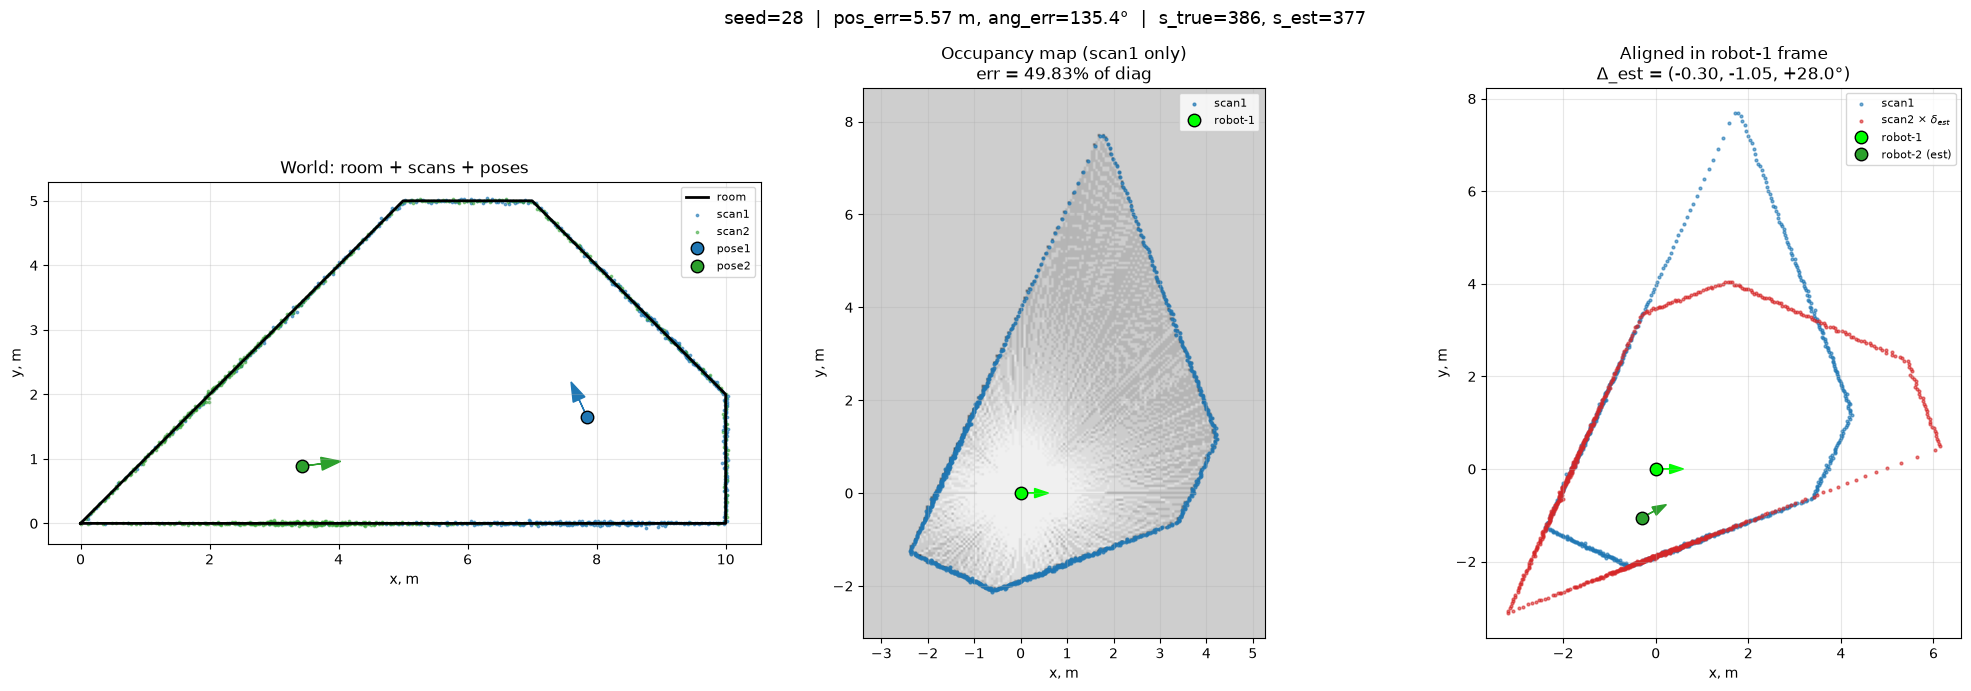


seed=17   pos_err=5.02 m, ang_err=135.0°
  delta_true: (-4.36, +1.95) |4.78|  θ=-61.9°
  delta_est:  (+0.55, +0.90) |1.05|  θ=+73.1°
  s_true =    361.9
  s_est  =    366.7
  Δ      =     -4.8   ✗ score неоднозначен


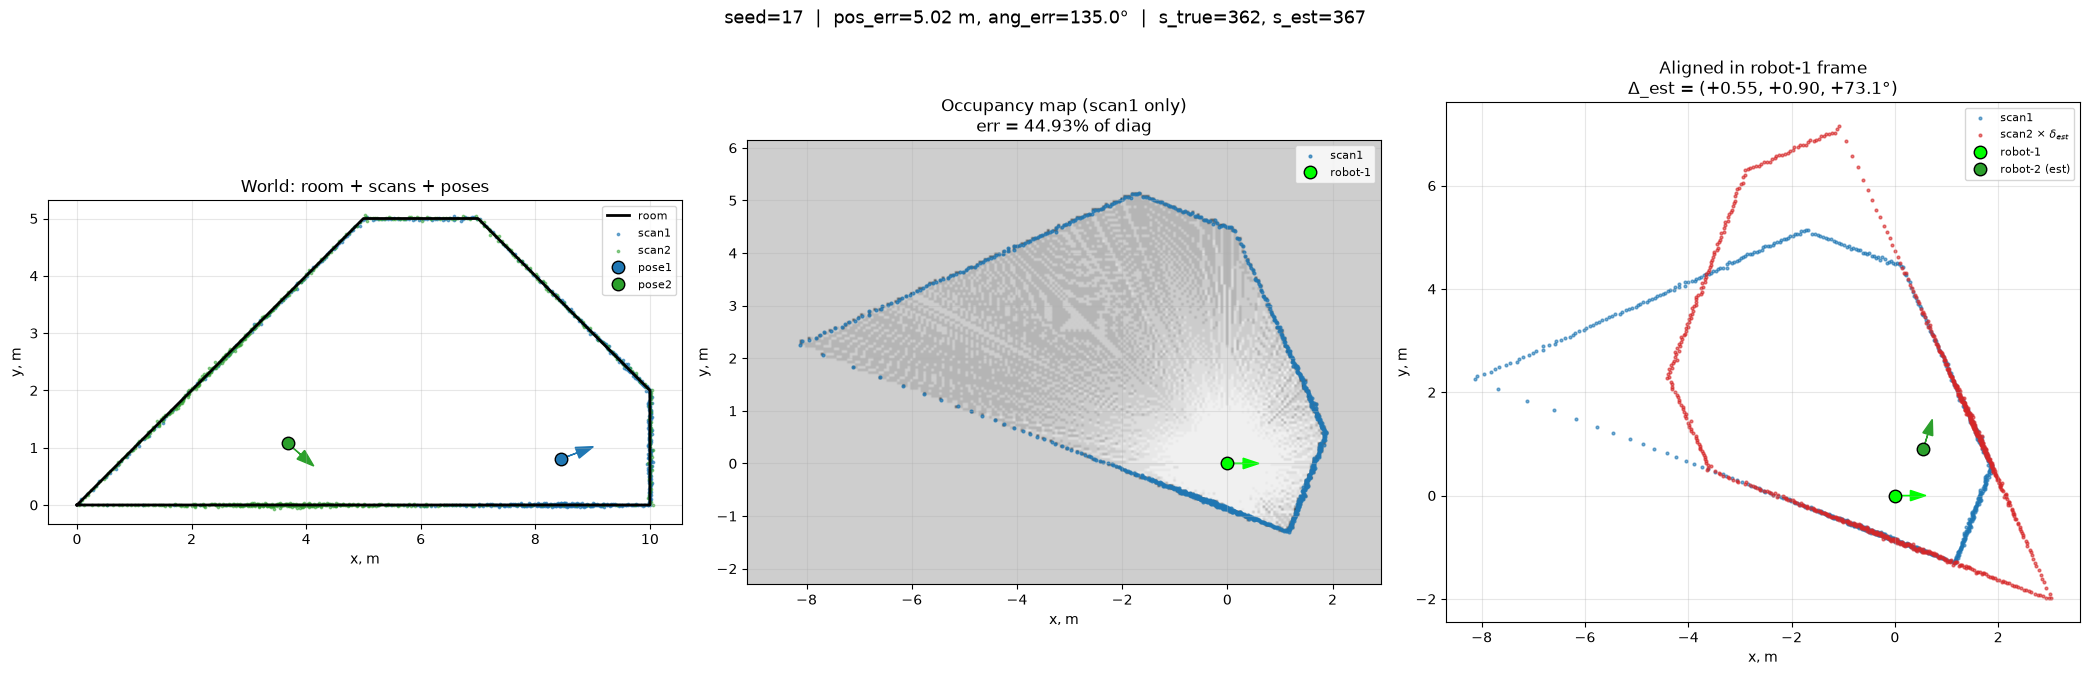


seed=29   pos_err=0.05 m, ang_err=0.1°
  delta_true: (-1.44, -1.08) |1.80|  θ=+1.0°
  delta_est:  (-1.40, -1.05) |1.75|  θ=+0.9°
  s_true =    422.8
  s_est  =    392.3
  Δ      =    +30.6   ✓ score ОК


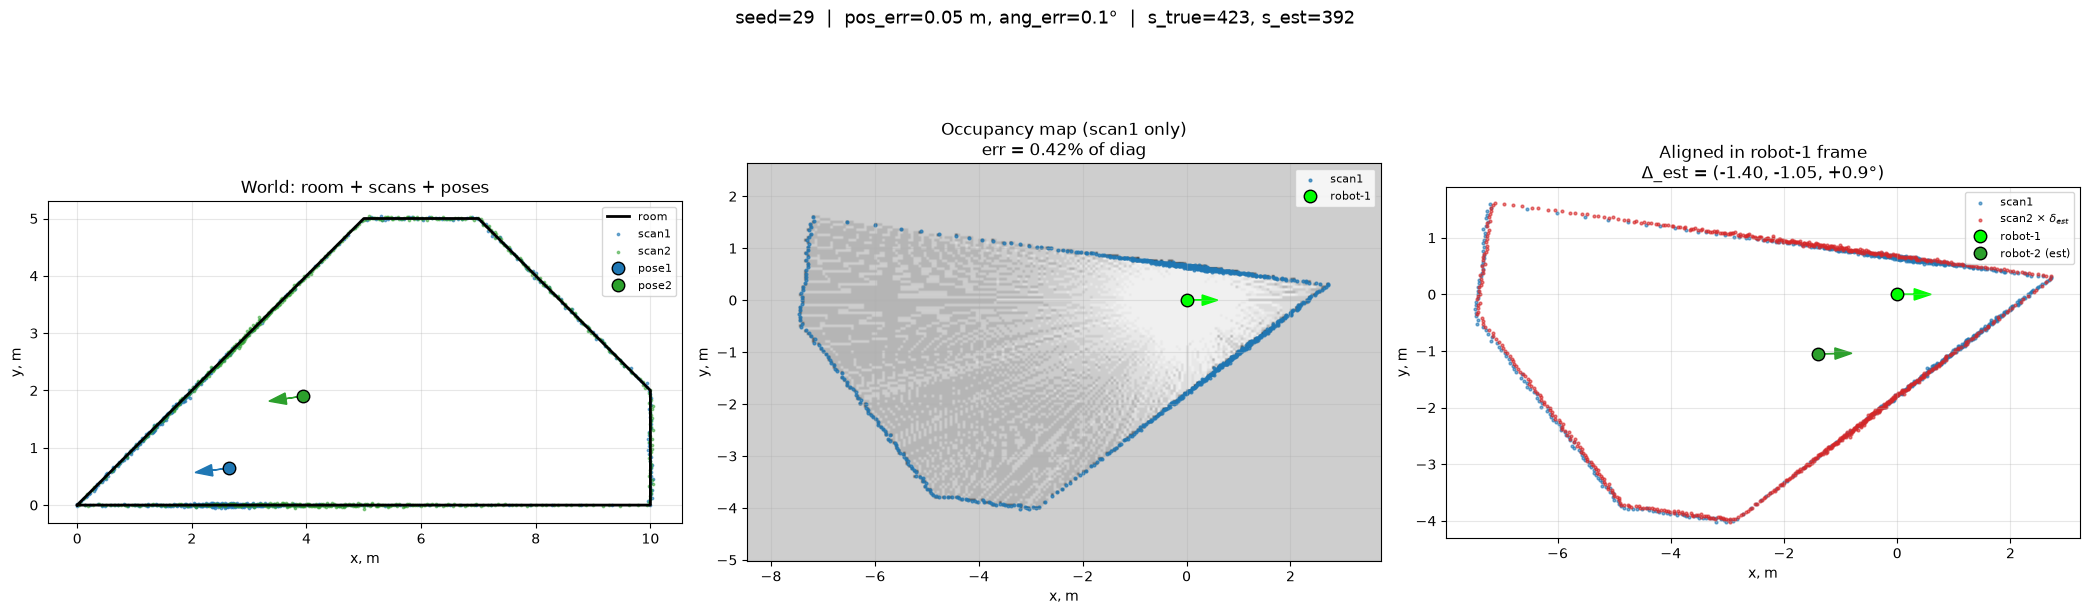

In [100]:
# room2 = Room(
#     polygon=[
#         Point(0.0, 0.0),
#         Point(10.0, 0.0),
#         Point(10.0, 2.0),
#         Point(7.0, 5.0),
#         Point(5.0, 5.0),
#     ],
#     columns=[
#         # Circle(Point(3.0, 2.5), 0.4),
#         # Circle(Point(6.5, 4.5), 0.7),
#     ],
# )
diag = diagnose_failing_seeds(ROOM, results, n_show=3, matcher=ScanMatcher())